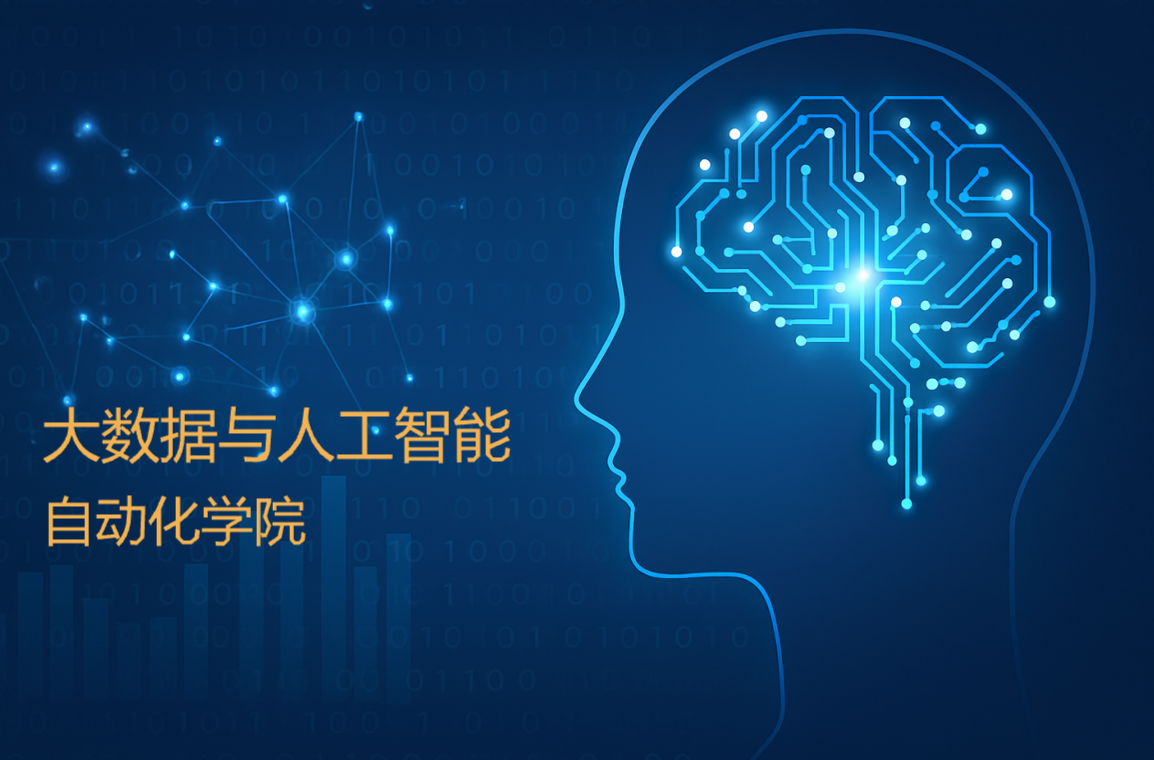
# 第2篇 Transformers 实战演练篇


- 在掌握了基础组件后，我们将通过9大具体任务（文本分类、NER、阅读理解、多项选择、文本相似度、检索机器人、预训练、摘要生成、对话机器人），深入讲解基于 Transformers 的 NLP 解决方案
- 并重点解决显存优化、长文本处理、数据对齐等实战中的痛点问题

* * *

## 第2.1课：基于 Transformers 的 NLP 解决方案与显存优化 (02.01)

### 课程概览

- 基础组件回顾（Pipeline, Tokenizer, Model, Datasets等）
    
- **核心重点**：Transformers 显存优化策略
    
- 显存优化实战演练
        

#### 2.1 显存去哪儿了？（原理深度解析）

在实战中，许多同学没有 4090 这样的高端显卡，可能只有 4G 或 8G 显存。为了在有限的资源下跑通 `BERT-Large` 这样的大模型（约 0.3B 参数），我们需要先搞清楚显存到底被谁吃掉了：

1. **模型权重 (Model Weights)**：
    
    - 模型参数本身占用的空间。在 FP32 精度下，每个参数占 4 字节。比如 `MacBERT-Large` 约 3.3 亿参数，光权重就要占不少空间。
        
2. **优化器状态 (Optimizer States)**：
    
    - 这是显存占用的“大户”。如果使用 AdamW 优化器，它需要保存一阶矩（动量）和二阶矩（方差）等状态，占用的空间往往是模型权重的 2 倍甚至更多（约 8 字节/参数）。
        
3. **梯度 (Gradients)**：
    
    - 在反向传播过程中，计算出来的梯度也需要存储，通常也是 4 字节/参数。
        
4. **前向激活值 (Forward Activations)**：
    
    - 这是显存的“隐形杀手”。模型在从前往后计算时，产生的中间层结果（中间变量）必须保存下来，用于反向传播计算梯度。
        
    - 它的大小与 **Batch Size** 和 **Sequence Length（序列长度）** 直接相关。序列越长（如 512 vs 64），中间要存的矩阵就越大，显存占用呈倍数增长。
        

#### 2.2 显存优化策略实战（代码与原理解析）

为了演示极限优化，我们使用 `hfl/chinese-macbert-large` 模型。在没有任何优化（Baseline: Batch=32, Length=128）的情况下，该模型占用约 **15.2GB** 显存。

为了在 **4G 显存** 环境下跑起来，我们将按顺序实施以下策略：

**策略一：梯度累加 (Gradient Accumulation)**

- **现象**：显存不够，Batch Size 无法设大。
    
- **原理**：我们将 `per_device_train_batch_size` 设为 **1**（极小），但让模型连续计算 **32** 次（steps）梯度而不更新参数，把这 32 次的梯度累加起来，再一次性更新。
    
- **效果**：等效于 Batch Size = 32。实测显存从 15.2GB 降至 **7.4GB**（降幅约 50%）。
    
- **代价**：由于无法充分利用 GPU 并行计算能力，训练时间会显著变长。
    

**策略二：梯度检查点 (Gradient Checkpointing)**

- **原理**：针对“前向激活值”的优化。这是一种“时间换空间”的策略。模型不再保存所有中间层的激活值，而是在反向传播需要用到某层数据时，临时重新计算一遍前向过程。
    
- **效果**：实测显存进一步降至 **7.2GB**。虽然在这个 Batch=1 的实验中降幅看似不明显，但在大 Batch 或大模型场景下效果非常显著。
    

**策略三：更换优化器 (Adafactor)**

- **原理**：针对“优化器状态”的优化。AdamW 需要为每个参数存两份状态（动量和方差）。Adafactor 优化器通过分层近似的方法，放弃存储完整的二阶矩，大幅减少显存占用。
    
- **效果**：实测显存从 7.2GB 骤降至 **约 5GB**。
    

**策略四：冻结参数 (Freezing)**

- **原理**：如果我们不需要训练整个 BERT 主干，只训练最后的全连接层（Classifier）。我们可以把 BERT 参数的 `requires_grad` 设为 `False`。
    
- **效果**：不计算梯度意味着不需要存梯度，也不需要优化器维护这些参数的状态。实测显存降至 **3.4GB**，成功达成 4G 显存跑 Large 模型的目录。而且训练速度也会变快。
    



### 代码实战：综合优化配置

接下来，我们将把前面提到的所有优化策略（梯度累加、梯度检查点、Adafactor、参数冻结）整合到一个完整的文本分类任务（情感分析）脚本中。

我们的目标是：在有限的显存下，训练参数量巨大的 `MacBERT-Large` 模型。

#### Step 1: 基础环境与数据准备

首先，我们需要加载数据并进行预处理。这里有一个隐含的优化点：**序列长度 (Sequence Length)**。

- **代码细节**：`max_length=32`。
    
- **优化原理**：我们在显存分析中提到，前向激活值与序列长度成正比。将长度从 128 或 512 缩减到 32，可以显著降低显存占用，虽然这可能会损失长文本的信息，但在情感分析这种短文本任务中通常是可以接受的。

In [1]:
import os
# 必须在导入 torch 之前设置， 这样系统只会看到第一张 GPU，Trainer 就不会使用多 GPU。
os.environ['CUDA_VISIBLE_DEVICES'] = '0'

from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from datasets import load_dataset
import torch

# 1. 加载数据集 (情感分析 ChnSentiCorp)
dataset = load_dataset("csv", data_files="./ChnSentiCorp_htl_all.csv", split="train")
dataset = dataset.filter(lambda x: x["review"] is not None)

# 2. 划分训练集和测试集
datasets = dataset.train_test_split(test_size=0.1)

# 3. 数据预处理
# 注意：这里加载的是本地路径的模型，你也可以直接写 "hfl/chinese-macbert-large"
model_path = "/3T/strange007/models/hfl_chinese-macbert-large" 
tokenizer = AutoTokenizer.from_pretrained(model_path)

def process_function(examples):
    # 【显存优化细节】max_length=32 
    # 极短的序列长度能大幅减少 Attention 矩阵的显存占用
    tokenized_examples = tokenizer(examples["review"], max_length=32, truncation=True, padding="max_length")
    tokenized_examples["labels"] = examples["label"]
    return tokenized_examples

tokenized_datasets = datasets.map(process_function, batched=True, remove_columns=datasets["train"].column_names)

c:\Users\stranger007\.conda\envs\teach\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Generating train split: 7766 examples [00:00, 112664.39 examples/s]
Filter: 100%|██████████| 7766/7766 [00:00<00:00, 138884.95 examples/s]


Dataset({
    features: ['label', 'review'],
    num_rows: 7765
})
Dataset({
    features: ['label', 'review'],
    num_rows: 7765
})
DatasetDict({
    train: Dataset({
        features: ['label', 'review'],
        num_rows: 6988
    })
    test: Dataset({
        features: ['label', 'review'],
        num_rows: 777
    })
})


OSError: Incorrect path_or_model_id: '/3T/strange007/models/hfl_chinese-macbert-large'. Please provide either the path to a local folder or the repo_id of a model on the Hub.

#### Step 2: 模型加载与评估函数

加载 `Large` 版本模型，并将其移动到指定的 GPU 上。

In [2]:
import evaluate
import os
import subprocess
import sys
from pathlib import Path

############################
# 这里是额外的模块，用来下载evaluate指标
############################

# 设置代理
os.environ['https_proxy'] = 'http://127.0.0.1:1081'
os.environ['http_proxy'] = 'http://127.0.0.1:1081'
os.environ['all_proxy'] = 'socks5://127.0.0.1:1080'
print("✅ 代理设置完成:")
print(f"  https_proxy: {os.environ['https_proxy']}")
print(f"  http_proxy: {os.environ['http_proxy']}")
print(f"  all_proxy: {os.environ['all_proxy']}")

# 设置evaluate离线缓存目录
cache_dir = Path('/3T/strange007/models/huggingface_cache')
cache_dir.mkdir(parents=True, exist_ok=True)
os.environ['HF_HOME'] = str(cache_dir)
os.environ['HF_EVALUATE_CACHE'] = str(cache_dir / 'evaluate')

print(f"✅ 设置evaluate离线缓存目录: {cache_dir}")

# 检查并安装必要的依赖
def check_and_install_dependencies():
    """检查并安装必要的依赖"""
    required_packages = ['scikit-learn', 'numpy', 'pandas', 'datasets', 'transformers', 'evaluate']
    
    print("检查依赖包...")
    missing_packages = []
    
    for package in required_packages:
        try:
            if package == 'scikit-learn':
                import sklearn
                print(f"✅ {package} 已安装")
            else:
                __import__(package)
                print(f"✅ {package} 已安装")
        except ImportError:
            missing_packages.append(package)
            print(f"❌ {package} 未安装")
    
    if missing_packages:
        print(f"\n需要安装的包: {missing_packages}")
        for package in missing_packages:
            try:
                print(f"正在安装 {package}...")
                # 使用代理安装pip包
                cmd = [sys.executable, '-m', 'pip', 'install', package, '--proxy', 'http://127.0.0.1:1081']
                subprocess.check_call(cmd)
                print(f"✅ {package} 安装完成")
            except subprocess.CalledProcessError as e:
                print(f"❌ {package} 安装失败: {e}")
                return False
    else:
        print("✅ 所有依赖包都已安装")
    
    return True

# 检查依赖
if not check_and_install_dependencies():
    print("❌ 依赖安装失败，请手动安装: pip install scikit-learn numpy pandas datasets transformers evaluate")

# 预下载evaluate指标到本地
def download_evaluate_metrics():
    """下载evaluate指标到本地"""
    metrics_to_download = ["accuracy", "f1", "precision", "recall"]
    
    print("开始预下载evaluate指标...")
    
    # 设置requests代理（evaluate库内部使用requests）
    import requests
    from requests.adapters import HTTPAdapter
    from urllib3.util.retry import Retry
    
    # 创建带代理的session
    session = requests.Session()
    session.proxies = {
        'http': 'http://127.0.0.1:1081',
        'https': 'http://127.0.0.1:1081'
    }
    
    # 设置重试策略
    retry_strategy = Retry(
        total=3,
        backoff_factor=1,
        status_forcelist=[429, 500, 502, 503, 504],
    )
    adapter = HTTPAdapter(max_retries=retry_strategy)
    session.mount("http://", adapter)
    session.mount("https://", adapter)
    
    # 临时替换全局的requests session
    original_get = requests.get
    original_post = requests.post
    
    def patched_get(*args, **kwargs):
        kwargs['proxies'] = session.proxies
        return original_get(*args, **kwargs)
    
    def patched_post(*args, **kwargs):
        kwargs['proxies'] = session.proxies
        return original_post(*args, **kwargs)
    
    requests.get = patched_get
    requests.post = patched_post
    
    try:
        for metric in metrics_to_download:
            try:
                print(f"正在下载: {metric}")
                # 这会触发下载并缓存到本地
                metric_obj = evaluate.load(metric)
                print(f"✅ {metric} 下载完成")
            except Exception as e:
                print(f"❌ {metric} 下载失败: {e}")
        
        print("✅ 所有指标下载完成")
    finally:
        # 恢复原始的requests方法
        requests.get = original_get
        requests.post = original_post

# 下载指标
download_evaluate_metrics()


############################
# 现在可以正常使用evaluate
############################
clf_metrics = evaluate.combine(["accuracy", "f1"])
print("✅ evaluate.combine 创建成功")

✅ 代理设置完成:
  https_proxy: http://127.0.0.1:1081
  http_proxy: http://127.0.0.1:1081
  all_proxy: socks5://127.0.0.1:1080
✅ 设置evaluate离线缓存目录: /3T/strange007/models/huggingface_cache
检查依赖包...
✅ scikit-learn 已安装
✅ numpy 已安装
✅ pandas 已安装
✅ datasets 已安装
✅ transformers 已安装
✅ evaluate 已安装
✅ 所有依赖包都已安装
开始预下载evaluate指标...
正在下载: accuracy
✅ accuracy 下载完成
正在下载: f1
✅ f1 下载完成
正在下载: precision
✅ precision 下载完成
正在下载: recall
✅ recall 下载完成
✅ 所有指标下载完成
✅ evaluate.combine 创建成功


In [3]:
import evaluate

# 1. 加载模型
model = AutoModelForSequenceClassification.from_pretrained(model_path)

# 指定使用第1张GPU（GPU 0）
if torch.cuda.is_available():
    device = torch.device("cuda:0")
    model = model.to(device)
    print(f"模型已移动到设备: {device}")

# 2. 加载评估指标 (Accuracy & F1)
# 如果网络受限，可以使用本地路径加载 metric 脚本
acc_metric = evaluate.load("./metric_accuracy.py")
f1_metirc = evaluate.load("./metric_f1.py")

def eval_metric(eval_predict):
    predictions, labels = eval_predict
    predictions = predictions.argmax(axis=-1)
    acc = acc_metric.compute(predictions=predictions, references=labels)
    f1 = f1_metirc.compute(predictions=predictions, references=labels)
    acc.update(f1)
    return acc

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at /3T/strange007/models/hfl_chinese-macbert-large and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


模型已移动到设备: cuda:0


#### Step 3: 核心配置 (TrainingArguments)

这是显存优化的**重头戏**。我们通过 `TrainingArguments` 激活了三项核心策略：**梯度累加**、**梯度检查点**和**Adafactor 优化器**。

In [4]:
train_args = TrainingArguments(
    output_dir="./checkpoints",      # 输出文件夹
    
    # --- 【策略一：梯度累加】 ---
    # 原理：显存不够，单次只能跑 batch=2？
    # 我们设置 batch=2，但让它累积 32 次梯度才更新一次参数。
    # 等效 Batch Size = 2 * 32 = 64。
    per_device_train_batch_size=2,   
    gradient_accumulation_steps=32,  
    
    # --- 【策略二：梯度检查点】 ---
    # 原理：以时间换空间。不保存中间激活值，反向传播需要时重算。
    # 这能极大降低 Large 模型的显存峰值。
    gradient_checkpointing=True,     
    
    # --- 【策略三：Adafactor 优化器】 ---
    # 原理：放弃保存占用巨大的优化器状态（动量+方差），
    # 相比 AdamW，它能节省几乎一半的显存。
    optim="adafactor",               
    
    per_device_eval_batch_size=4,    # 验证时的batch_size
    num_train_epochs=1,              # 训练轮数
    logging_steps=10,                
    eval_strategy="epoch",           # 这里的 key 是 eval_strategy (新版HF)
    save_strategy="epoch",           
    save_total_limit=3,              
    learning_rate=2e-5,              
    weight_decay=0.001,              
    metric_for_best_model="f1",      
    load_best_model_at_end=True,     
    
    # 避免多 GPU 环境下的一些内存锁定问题
    dataloader_pin_memory=False,     
    ddp_find_unused_parameters=False 
)

#### Step 4: 参数冻结与训练执行

在初始化 `Trainer` 之前，我们执行**第四个策略：冻结参数**。

- **原理**：`param.requires_grad = False`。这意味着 BERT 主干网络的参数将不再更新。这不仅直接去掉了这些参数的梯度存储需求（显存减半），还让优化器不需要维护这些参数的状态（显存再减）。我们只训练最后那层小小的分类头（Classifier）。

In [5]:
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '0'

from transformers import DataCollatorWithPadding

# --- 【策略四：参数冻结】 ---
# 遍历 BERT 主干的参数，关闭梯度计算
for name, param in model.bert.named_parameters():
    param.requires_grad = False

# 创建 Trainer
trainer = Trainer(
    model=model, 
    args=train_args, 
    tokenizer=tokenizer,
    train_dataset=tokenized_datasets["train"], 
    eval_dataset=tokenized_datasets["test"], 
    data_collator=DataCollatorWithPadding(tokenizer=tokenizer),
    compute_metrics=eval_metric
)

# 开始训练
trainer.train()

# 训练后评估
print(trainer.evaluate(tokenized_datasets["test"]))

/3T/strange007/miniconda3/envs/teach/lib/python3.12/site-packages/torch/_dynamo/eval_frame.py:929: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. In version 2.5 we will raise an exception if use_reentrant is not passed. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)
/3T/strange007/miniconda3/envs/teach/lib/python3.12/site-packages/torch/utils/checkpoint.py:85: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  warnings.warn(


Epoch,Training Loss,Validation Loss,Accuracy,F1
0,0.679800,0.677466,0.624196,0.751278


{'eval_loss': 0.6774658560752869, 'eval_accuracy': 0.6241956241956242, 'eval_f1': 0.7512776831345827, 'eval_runtime': 3.3619, 'eval_samples_per_second': 231.117, 'eval_steps_per_second': 58.002, 'epoch': 0.998282770463652}


#### Step 5: 模型预测与推理

训练完成后，我们可以通过 PyTorch 原生方式或 Hugging Face 的 `pipeline` 进行推理。注意在推理时也要注意设备管理。
- model.eval()表示现在推理，不进行梯度计算

In [7]:
# 方式一：原生 PyTorch 推理
sen = "我觉得这家酒店不错，饭很好吃！"
id2_label = {0: "差评！", 1: "好评！"}

model.eval()
with torch.inference_mode():
    inputs = tokenizer(sen, return_tensors="pt")
    # 确保输入数据也移动到对应的 GPU 上
    device = torch.device("cuda:0")
    inputs = {k: v.to(device) for k, v in inputs.items()}
    
    logits = model(**inputs).logits
    pred = torch.argmax(logits, dim=-1)
    print(f"输入：{sen}\n模型预测结果:{id2_label.get(pred.item())}")

# 方式二：使用 Pipeline
from transformers import pipeline

model.config.id2label = id2_label
# device=0 对应 cuda:0
pipe = pipeline("text-classification", model=model, tokenizer=tokenizer, device=0)
print(pipe(sen))

输入：我觉得这家酒店不错，饭很好吃！
模型预测结果:好评！
[{'label': '好评！', 'score': 0.52419513463974}]



* * *

## 第2.2课：实战演练之命名实体识别 NER (02.02)

### 核心教学内容

- 本章节我们将依照完整的机器学习流程（数据加载 -> 预处理 -> 模型构建 -> 评估设定 -> 训练 -> 推理），手把手实现一个基于 Transformer 的命名实体识别（NER）系统。

- NER 任务
    - 与文本分类不同，它属于**序列标注**任务。
    - 我们需要对句子中的**每一个 Token** 进行分类（如：B-PER, I-LOC, O）。 
    - 我们使用 `peoples_daily_ner`（人民日报）数据集，包含人名（PER）、组织名（ORG）和地名（LOC）三类实体。
        


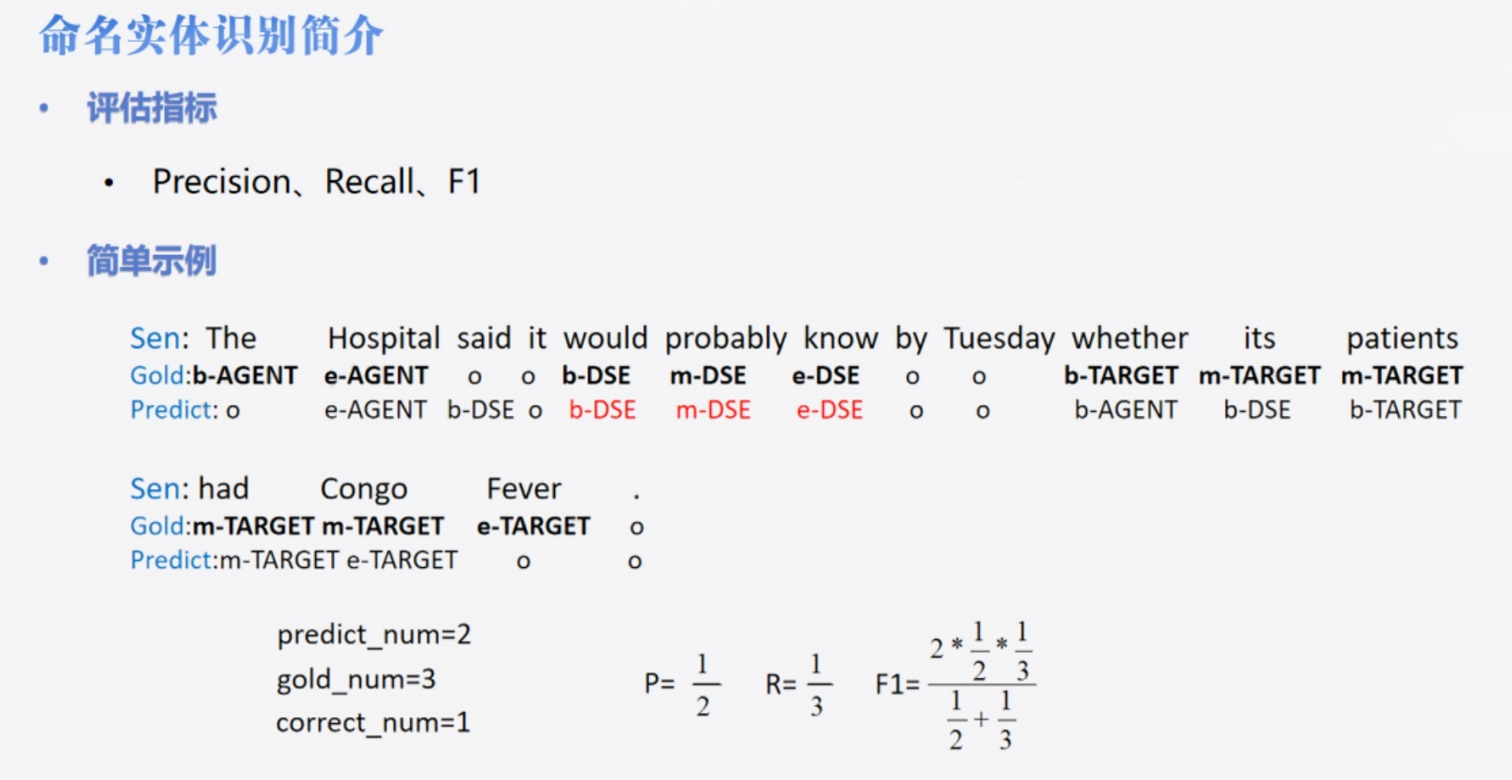

## **命名实体识别（NER, Named Entity Recognition）如何评估**模型的效果。

### 1\. 评估指标 (Evaluation Metrics)

NER 任务通常使用以下三个指标来衡量模型的好坏：

- **Precision (精确率/查准率)**：预测出的实体中，有多少是正确的？
    
- **Recall (召回率/查全率)**：所有真实的实体中，有多少被模型找出来了？
    
- **F1 Score (F1值)**：精确率和召回率的调和平均数，用于综合评估模型的性能。
    

### 2\. 简单示例 (Simple Example)

这里展示了一个具体的句子，以及标准答案（Gold）和模型预测结果（Predict）的对比。

#### **标注符号解释：**

这里使用的是一种常见的序列标注方法（图片里面是 BME 编码变体）：

- **B-XXX**: 实体开始 (Begin)
    
- **M-XXX**: 实体中间 (Middle)
    
- **E-XXX**: 实体结束 (End)
    
- **O**: 非实体 (Outside)
    
- **后缀 (AGENT, DSE, TARGET)**：代表实体的类别（例如：DSE可能指直接主观表达，Target指评价对象，Agent指评价主体，这是观点挖掘领域的常见实体类型）。
    

#### **行内容解析：**

- **Sen (Sentence)**: 原始句子内容（"The Hospital said it would probably know by Tuesday..."）。
    
- **Gold (Standard/Truth)**: **人工标注的标准答案**。
    
- **Predict**: **模型的预测结果**。
    

#### **具体的计算逻辑（图片下半部分）：**

图片底部展示了如何根据上面的对比来计算 P、R、F1：

1. **统计数量：**
    
    - **gold_num = 3**：表示在标准答案（Gold）行中，一共有 **3个** 完整的实体。
        
    - **predict_num = 2**：表示模型在预测（Predict）行中，一共识别出了 **2个** 实体（不管对错，只要模型认为是一个完整实体就算）。
        
    - **correct_num = 1**：表示在预测出的实体中，只有 **1个** 是完全正确的（即：预测的“开始位置”、“结束位置”和“实体类别”都必须和 Gold 完全一致）。
        
2. **计算公式：**
    
    - **P (Precision) = $1/2$**
        
        - **公式**：$Correct / Predict$
            
        - **含义**：模型预测了2个，其中1个是对的，所以精确率是 50%。
            
    - **R (Recall) = $1/3$**
        
        - **公式**：$Correct / Gold$
            
        - **含义**：原本有3个正确答案，模型只找对了1个，所以召回率是 33.3%。
            
    - **F1 = $\frac{2 \times \frac{1}{2} \times \frac{1}{3}}{\frac{1}{2} + \frac{1}{3}}$**
    
    - **公式**：$2 \times (P \times R) / (P + R)$
            
        - **含义**：这是 P 和 R 的调和平均数，算出来结果应该是 0.4 (或 2/5)。


* * *

### 2\. 关于 `peoples_daily_ner`（人民日报）数据集

这是中文 NLP 领域非常经典的一个数据集，主要用于训练模型识别中文新闻中的特定实体。

#### 包含的三类实体

根据 的实战脚本描述，该数据集主要关注以下三类：

1. **PER (Person)**：人名。
    
    - 例如：*小明*、*张三*、*特朗普*。
        
2. **LOC (Location)**：地名。
    
    - 例如：*北京*、*中国*、*黑龙江*。
        
3. **ORG (Organization)**：组织机构名。
    
    - 例如：*百度*、*教育部*、*高盛集团*。
        

#### 数据在代码中的样子

在 Python 代码中加载该数据集后， 会看到它已经被数字化处理了。

- `tokens`：原始汉字列表。
    
    - `['海', '钓', '比', '赛', ...]`
        
- `ner_tags`：对应的数字标签列表。
    
    - `[0, 0, 0, 0, ...]`
        

数字与标签的映射（Mapping）：

为了让计算机处理，字符串标签（如 B-PER）会被映射为数字（ID）。通常在数据集的 features 属性中可以找到这种映射关系。例如：

- `0` -> `O`
    
- `1` -> `B-PER`
    
- `2` -> `I-PER`
    
- `3` -> `B-ORG`
    
- `4` -> `I-ORG`
    
- `5` -> `B-LOC`
    
- `6` -> `I-LOC`
    


## 随堂作业

### 5.2.2 在命名实体识别NER的 BIO 标注体系中，’I-LOC’ 标签代表什么含义？



实战中的关键点：

在代码实战中，需要特别注意标签数量（num_labels）。如果数据集有 7 种标签（O + 3种实体的B/I），那么在加载模型时必须指定 num_labels=7，否则模型默认是二分类，会导致维度报错。

In [16]:
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '0'

import evaluate
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForTokenClassification, TrainingArguments, Trainer, DataCollatorForTokenClassification

from datasets import DatasetDict
ner_datasets = DatasetDict.load_from_disk("ner_data")
ner_datasets


DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 20865
    })
    validation: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 2319
    })
    test: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 4637
    })
})

In [18]:
ner_datasets["train"][0]


{'id': '0',
 'tokens': ['海',
  '钓',
  '比',
  '赛',
  '地',
  '点',
  '在',
  '厦',
  '门',
  '与',
  '金',
  '门',
  '之',
  '间',
  '的',
  '海',
  '域',
  '。'],
 'ner_tags': [0, 0, 0, 0, 0, 0, 0, 5, 6, 0, 5, 6, 0, 0, 0, 0, 0, 0]}

In [19]:
ner_datasets["train"].features

{'id': Value(dtype='string', id=None),
 'tokens': Sequence(feature=Value(dtype='string', id=None), length=-1, id=None),
 'ner_tags': Sequence(feature=ClassLabel(names=['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC'], id=None), length=-1, id=None)}

In [12]:
label_list = ner_datasets["train"].features["ner_tags"].feature.names
label_list

['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']

#### 2.2 难点突破：数据预处理与标签对齐

这是 NER 任务中最核心的难点。原始数据通常是已经分好词的列表（例如中文的一个字一个元素），而 Tokenizer 在处理时可能会产生子词（Subword）或添加特殊符号（[CLS], [SEP]），导致 Token 数量与原始 Label 数量不一致。

**解决方案：**

1. `is_split_into_words=True`：告诉 Tokenizer 输入已经是切分好的列表，不要再做全句分词。
    
2. `word_ids()`：利用此方法获取 Token 到原始词的映射，从而实现标签对齐。
    
3. **特殊符号处理**：将 [CLS] 和 [SEP] 的 Label 设为 **\-100**，PyTorch 的损失函数默认会忽略该值。

In [22]:
# ## Step3 数据集预处理

# tokenizer = AutoTokenizer.from_pretrained("hfl/chinese-macbert-base")
model_path = "/3T/strange007/models/hfl_chinese-macbert-base"
tokenizer = AutoTokenizer.from_pretrained(model_path)

# 对于已经做好tokenize的数据，要指定is_split_into_words参数为True
tokenizer(ner_datasets["train"][0]["tokens"], is_split_into_words=True)   

res = tokenizer("interesting word")
res



{'input_ids': [101, 10673, 12865, 12921, 8181, 8681, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1]}

In [23]:
res.word_ids()


[None, 0, 0, 0, 0, 1, None]

In [24]:
# 借助word_ids 实现标签映射
def process_function(examples):
    tokenized_exmaples = tokenizer(examples["tokens"], max_length=128, truncation=True, is_split_into_words=True)
    labels = []

    for i, label in enumerate(examples["ner_tags"]):
        word_ids = tokenized_exmaples.word_ids(batch_index=i)
        label_ids = []
        for word_id in word_ids:
            if word_id is None:
                label_ids.append(-100)
            else:
                label_ids.append(label[word_id])
        labels.append(label_ids)
    tokenized_exmaples["labels"] = labels
    return tokenized_exmaples


In [25]:
tokenized_datasets = ner_datasets.map(process_function, batched=True)
tokenized_datasets


Map:   0%|          | 0/20865 [00:00<?, ? examples/s]

Map:   0%|          | 0/2319 [00:00<?, ? examples/s]

Map:   0%|          | 0/4637 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'ner_tags', 'input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 20865
    })
    validation: Dataset({
        features: ['id', 'tokens', 'ner_tags', 'input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 2319
    })
    test: Dataset({
        features: ['id', 'tokens', 'ner_tags', 'input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 4637
    })
})

In [26]:
print(tokenized_datasets["train"][0])

{'id': '0', 'tokens': ['海', '钓', '比', '赛', '地', '点', '在', '厦', '门', '与', '金', '门', '之', '间', '的', '海', '域', '。'], 'ner_tags': [0, 0, 0, 0, 0, 0, 0, 5, 6, 0, 5, 6, 0, 0, 0, 0, 0, 0], 'input_ids': [101, 3862, 7157, 3683, 6612, 1765, 4157, 1762, 1336, 7305, 680, 7032, 7305, 722, 7313, 4638, 3862, 1818, 511, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], 'labels': [-100, 0, 0, 0, 0, 0, 0, 0, 5, 6, 0, 5, 6, 0, 0, 0, 0, 0, 0, -100]}


## 以上代码分析

假设我们的原始数据样本如下（**一个包含“组织机构名”实体的句子**）：

- **原始单词列表 (**`tokens`): `["他", "就职", "于", "亚马逊"]`
    
- **原始标签 (**`ner_tags`): `[O, O, O, B-ORG]`
    
    - 注：`O` 代表非实体，`B-ORG` 代表组织机构实体的开始。
        
    - 注意：这里原始列表长度为 **4**，标签长度也是 **4**。
        

* * *

### 第一步：分词器处理 (`tokenizer`)

代码：

Python

```
tokenized_examples = tokenizer(
    examples["tokens"], 
    max_length=128, 
    truncation=True, 
    is_split_into_words=True
)
```

原理分析：

由于使用的是中文 BERT（如 chinese-macbert-base），它通常是\*\*按字（Character-based）\*\*分词的。

- “他” -> `['他']` （没变）
    
- “就职” -> `['就', '职']` （**1个词被拆成了2个Token**）
    
- “于” -> `['于']` （没变）
    
- “亚马逊” -> `['亚', '马', '逊']` （**1个词被拆成了3个Token**）
    

**执行结果 (**`input_ids` 对应的 Token)：

Python

```
# 自动加上了 [CLS] 和 [SEP]
tokens = ['[CLS]', '他', '就', '职', '于', '亚', '马', '逊', '[SEP]']
```

此时，**输入长度变成了 9**，而我们原始标签只有 **4** 个，这就导致了长度不匹配，需要进行下一步对齐。

* * *

### 第二步：获取映射关系 (`word_ids`)

代码：

Python

```
word_ids = tokenized_examples.word_ids(batch_index=i)
```

原理分析：

word_ids 告诉我们每一个 Token 到底属于原始列表中的第几个词（索引）。

执行结果：

对应上面的 tokens ['[CLS]', '他', '就', '职', '于', '亚', '马', '逊', '[SEP]']，生成的 word_ids 是：

<table><tbody><tr><td><p><strong>Token</strong></p></td><td><p><strong>[CLS]</strong></p></td><td><p><strong>他</strong></p></td><td><p><strong>就</strong></p></td><td><p><strong>职</strong></p></td><td><p><strong>于</strong></p></td><td><p><strong>亚</strong></p></td><td><p><strong>马</strong></p></td><td><p><strong>逊</strong></p></td><td><p><strong>[SEP]</strong></p></td></tr><tr><td><p><strong>word_id</strong></p></td><td><p><strong>None</strong></p></td><td><p><strong>0</strong></p></td><td><p><strong>1</strong></p></td><td><p><strong>1</strong></p></td><td><p><strong>2</strong></p></td><td><p><strong>3</strong></p></td><td><p><strong>3</strong></p></td><td><p><strong>3</strong></p></td><td><p><strong>None</strong></p></td></tr></tbody></table>

- **None**: 特殊字符，不属于任何原词。
    
- **0**: 对应原词第1个 `["他"]`
    
- **1**: 对应原词第2个 `["就职"]` （因为“就”和“职”都属于“就职”，所以都是 1）
    
- **2**: 对应原词第3个 `["于"]`
    
- **3**: 对应原词第4个 `["亚马逊"]`
    

* * *

### 第三步：标签对齐循环 (`for word_id in word_ids`)

代码逻辑：

Python

```
for word_id in word_ids:
    if word_id is None:
        label_ids.append(-100)
    else:
        label_ids.append(label[word_id]) # label[1] 就是 "就职" 的标签 O
                                         # label[3] 就是 "亚马逊" 的标签 B-ORG
```

**原理分析（逐个 Token 走一遍）：**

1. **Token:** `[CLS]`
    
    - `word_id`: `None`
        
    - **操作**: 设为 **\-100** (忽略 Loss)
        
2. **Token:** `他`
    
    - `word_id`: `0`
        
    - **操作**: 取 `label[0]` -> **O**
        
3. **Token:** `就`
    
    - `word_id`: `1`
        
    - **操作**: 取 `label[1]` -> **O**
        
4. **Token:** `职`
    
    - `word_id`: `1` (还是指向“就职”)
        
    - **操作**: 取 `label[1]` -> **O**
        
    - *注：这里把“就”和“职”都标记为了 O*
        
5. **Token:** `于`
    
    - `word_id`: `2`
        
    - **操作**: 取 `label[2]` -> **O**
        
6. **Token:** `亚`
    
    - `word_id`: `3`
        
    - **操作**: 取 `label[3]` -> **B-ORG**
        
7. **Token:** `马`
    
    - `word_id`: `3` (还是指向“亚马逊”)
        
    - **操作**: 取 `label[3]` -> **B-ORG**
        
8. **Token:** `逊`
    
    - `word_id`: `3` (还是指向“亚马逊”)
        
    - **操作**: 取 `label[3]` -> **B-ORG**
        
    - *注：这里采取了策略——把“亚马逊”拆出来的三个字全部标记为 B-ORG*
        
9. **Token:** `[SEP]`
    
    - `word_id`: `None`
        
    - **操作**: 设为 **\-100**
        

* * *

### 最终结果对比

通过这套代码，我们成功把**长度为 4** 的原始标签，转换成了**长度为 9** 的对齐标签：

- **原始标签**: `[O, O, O, B-ORG]`
    
- **模型输入 Labels**: `[-100, O, O, O, O, B-ORG, B-ORG, B-ORG, -100]`
    

总结：

这样处理后，每一个输入给 BERT 的 Token 都有了一个合理的标签（或者被标记为忽略），模型就可以愉快地计算 Loss 并进行梯度下降了。

#### 2.3 模型构建与配置

- 在加载预训练模型时，有一个非常容易报错的细节：**必须指定** `num_labels`。
- 如果不指定，模型默认会初始化为二分类（num_labels=2），这会导致后续训练时维度不匹配（Shape Error）。

In [27]:
# ## Step4 创建模型
# 对于所有的非二分类任务，切记要指定num_labels，否则就会device错误

# model = AutoModelForTokenClassification.from_pretrained("hfl/chinese-macbert-base", num_labels=len(label_list))
model_path = "/3T/strange007/models/hfl_chinese-macbert-base"
model = AutoModelForTokenClassification.from_pretrained(model_path, num_labels=len(label_list))
model.config.num_labels

Some weights of BertForTokenClassification were not initialized from the model checkpoint at /3T/strange007/models/hfl_chinese-macbert-base and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


7

In [28]:
label_list

['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']

#### 2.4 评估指标：Seqeval

- NER 任务不能简单看 Accuracy，因为大部分标签都是 "O"（非实体），准确率通常虚高。
- 我们需要计算实体的 Precision, Recall 和 F1 值。
- 这里使用 `seqeval` 库，并支持 IOB2 格式。

在计算前，我们需要将模型预测的数字 ID 还原回字符串标签（如 "B-PER"），并剔除掉 `-100` 的部分。

In [29]:
# ## Step5 创建评估函数

# 这里方便大家加载，替换成了本地的加载方式，无需额外下载
seqeval = evaluate.load("seqeval_metric.py")
seqeval

import numpy as np
def eval_metric(pred):
    predictions, labels = pred
    predictions = np.argmax(predictions, axis=-1)

    # 将id转换为原始的字符串类型的标签
    true_predictions = [
        [label_list[p] for p, l in zip(prediction, label) if l != -100]
        for prediction, label in zip(predictions, labels) 
    ]

    true_labels = [
        [label_list[l] for p, l in zip(prediction, label) if l != -100]
        for prediction, label in zip(predictions, labels) 
    ]

    result = seqeval.compute(predictions=true_predictions, references=true_labels, mode="strict", scheme="IOB2")
    return {
        "f1": result["overall_f1"]
    }

    
# ## Step6 配置训练参数
args = TrainingArguments(
    output_dir="models_for_ner",
    per_device_train_batch_size=64,
    per_device_eval_batch_size=128,
    eval_strategy="epoch",
    save_strategy="epoch",
    metric_for_best_model="f1",
    load_best_model_at_end=True,
    logging_steps=50,
    num_train_epochs=1
)

## 以上代码分析

**NER 模型评估阶段** 的标准写法。它的核心任务是将模型输出的 **数字 ID** 还原成 **真实的标签字符串**，并剔除掉不需要评估的特殊字符（如 `[CLS]`, `[SEP]`, `PAD`），最后计算 F1 分数。

我们继续使用你指定的例子：

- **原始句子**：`["他", "就职", "于", "亚马逊"]`
    
- **分词后 (9个Token)**：`['[CLS]', '他', '就', '职', '于', '亚', '马', '逊', '[SEP]']`
    
- **假设** `label_list`：`['O', 'B-ORG', 'I-ORG', ...]` （假设索引：0->O, 1->B-ORG）
    

* * *

### 1\. 输入数据的样子 (`pred`)

评估函数的输入 `pred` 是一个元组 `(predictions, labels)`。

- `predictions` (模型预测)：形状是 `[Batch_Size, Seq_Len, Num_Labels]` 的概率分布（Logits）。
    
    - 比如模型对“亚”这个字的预测可能是 `[0.1, 0.8, 0.1]` (概率最高的是索引1 B-ORG)。
        
- `labels` (真实标签)：形状是 `[Batch_Size, Seq_Len]` 的整数索引。
    
    - 这就是我们在数据预处理阶段生成的 `input_ids` 对应的标签序列。
        
    - 例子中的真实 labels：
        
        [-100, 0, 0, 0, 0, 1, 1, 1, -100]
        
        (对应：[CLS], 他, 就, 职, 于, 亚, 马, 逊, [SEP])
        

* * *

### 2\. 代码逐行解析

#### 第一步：获取预测结果

Python

```
predictions = np.argmax(predictions, axis=-1)
```

- **原理**：模型输出的是每个标签的概率值。`argmax` 帮我们取出概率最大的那个索引，即模型认为“最可能”的标签 ID。
    
- **结果**：现在 `predictions` 和 `labels` 形状一样了，都是 `[Batch_Size, Seq_Len]` 的整数列表。
    
- **假设模型预测结果**（假设模型还没训练好，中间预测错了一个字）：
    
    - `[-100, 0, 0, 0, 0, 1, 0, 1, -100]`
        
    - *(注意：模型对* `[CLS]` 位置也会有预测输出，虽然没意义，比如它预测了 -100 或者其他随机值)
        

#### 第二步：过滤与还原 (核心循环)

Python

```
# 遍历每一个样本 (prediction_ids 是预测序列, label_ids 是真实序列)
for prediction_ids, label_ids in zip(predictions, labels):
    ...
    # 遍历序列中的每一个 Token
    for p_id, l_id in zip(prediction_ids, label_ids):
        
        # 【关键点】 过滤掉 -100
        if l_id != -100:
            # ID 转 字符串
            single_true_predictions.append(label_list[p_id])
            single_true_labels.append(label_list[l_id])
```

**为什么要这样写？**

1. **过滤垃圾数据 (**`-100`)：
    
    - 在预处理阶段，我们将 `[CLS]`, `[SEP]` 和 `Padding` 的标签设为了 `-100`。
        
    - **如果不过滤**：`seqeval` 会把 `[CLS]` 当作一个实体去评估，这会导致指标虚高或虚低（完全没有意义）。
        
    - **过滤后**：我们只保留了真正有意义的文本内容：“他就职于亚马逊”。
        
2. **ID 转字符串 (**`label_list[id]`)：
    
    - `seqeval` 库计算指标时，**必须接收字符串列表**（如 `['B-ORG', 'O']`），因为它需要解析 `B-`, `I-` 前缀来确定实体的边界。如果只给数字 `1`，它不知道这是 Begin 还是 Inside。
        

* * *

### 3\. 全程图解演示 (Visual Walkthrough)

让我们看看循环内部发生了什么：

<table><tbody><tr><td><p><strong>Token</strong></p></td><td><p><strong>真实 Label ID (l_id)</strong></p></td><td><p><strong>模型预测 ID (p_id)</strong></p></td><td><p><strong>判断 l_id != -100</strong></p></td><td><p><strong>动作</strong></p></td><td><p><strong>存入列表的结果 (String)</strong></p></td></tr><tr><td><p><code>[CLS]</code></p></td><td><p><strong>-100</strong></p></td><td><p><em>随机值</em></p></td><td><p>❌ False</p></td><td><p><strong>跳过</strong></p></td><td><p>(无)</p></td></tr><tr><td><p><code>他</code></p></td><td><p>0</p></td><td><p>0</p></td><td><p>✅ True</p></td><td><p>转换并添加</p></td><td><p><code>pred=['O']</code>, <code>label=['O']</code></p></td></tr><tr><td><p><code>就</code></p></td><td><p>0</p></td><td><p>0</p></td><td><p>✅ True</p></td><td><p>转换并添加</p></td><td><p><code>pred=['O', 'O']</code>...</p></td></tr><tr><td><p><code>职</code></p></td><td><p>0</p></td><td><p>0</p></td><td><p>✅ True</p></td><td><p>转换并添加</p></td><td><p><code>pred</code>增加 'O'</p></td></tr><tr><td><p><code>于</code></p></td><td><p>0</p></td><td><p>0</p></td><td><p>✅ True</p></td><td><p>转换并添加</p></td><td><p><code>pred</code>增加 'O'</p></td></tr><tr><td><p><code>亚</code></p></td><td><p><strong>1 (B-ORG)</strong></p></td><td><p><strong>1</strong></p></td><td><p>✅ True</p></td><td><p>转换并添加</p></td><td><p><code>pred</code>增加 'B-ORG', <code>label</code>增加 'B-ORG'</p></td></tr><tr><td><p><code>马</code></p></td><td><p><strong>1 (B-ORG)</strong></p></td><td><p><strong>0 (O)</strong> (预测错了)</p></td><td><p>✅ True</p></td><td><p>转换并添加</p></td><td><p><code>pred</code>增加 'O', <code>label</code>增加 'B-ORG'</p></td></tr><tr><td><p><code>逊</code></p></td><td><p><strong>1 (B-ORG)</strong></p></td><td><p><strong>1</strong></p></td><td><p>✅ True</p></td><td><p>转换并添加</p></td><td><p><code>pred</code>增加 'B-ORG', <code>label</code>增加 'B-ORG'</p></td></tr><tr><td><p><code>[SEP]</code></p></td><td><p><strong>-100</strong></p></td><td><p><em>随机值</em></p></td><td><p>❌ False</p></td><td><p><strong>跳过</strong></p></td><td><p>(无)</p></td></tr></tbody></table>

**循环结束后的最终列表：**

- `true_predictions`: `[['O', 'O', 'O', 'O', 'B-ORG', 'O', 'B-ORG']]`
    
- `true_labels`: `[['O', 'O', 'O', 'O', 'B-ORG', 'B-ORG', 'B-ORG']]`
    

* * *

### 4\. 计算指标 (`seqeval.compute`)

Python

```
result = seqeval.compute(
    predictions=true_predictions, 
    references=true_labels, 
    mode="strict", 
    scheme="IOB2"
)
```

原理分析：

seqeval 是专门用于序列标注的评估库。它比普通的 Accuracy 厉害在它是基于“实体”层级评估的，而不是“字符”层级。

在上面的例子中：

- **真实实体**：`亚马逊` (由 3 个 B-ORG 组成，或者标准的 B-I-I 结构)
    
- **预测实体**：因为中间断开了（变成 `B-ORG`, `O`, `B-ORG`），`seqeval` 可能会认为模型预测出了两个单字的 Organization，或者完全没预测对（取决于 scheme）。
    

**参数解释：**

- `scheme="IOB2"`：告诉评估器你的标签格式。如果你的数据是 `B-ORG` 开头，后面跟着 `I-ORG`，就必须指定这个，否则评估可能会出错。
    
    - *注：你之前的预处理代码是“全部继承标签”，即“亚/马/逊”都是* `B-ORG`。这其实不符合标准的 BIO 格式（标准应该是 B, I, I）。如果直接这样送进去评估，F1 分数可能会很低，因为 `seqeval` 找不到连续的实体。通常在预处理时，我们会把非首字转为 `I-ORG`，或者在评估前手动修正一下。
        
- `mode="strict"`：严格模式。如果预测出了 `I-ORG` 但前面没有 `B-ORG`，直接算错。
    

### 总结

这段代码之所以这样写，是为了完成 **“去噪”** 和 **“翻译”** 两个工作：

1. **去噪**：剔除 `[CLS]`, `[SEP]` 这种占位符，只保留真实文本的评估结果。
    
2. **翻译**：把模型输出的冷冰冰的数字索引，翻译成 `seqeval` 能看懂的 `B-PER`, `I-LOC` 等语义标签，从而算出精准的 F1 分数。

#### 2.5 训练器配置与执行

使用 `DataCollatorForTokenClassification` 来动态对齐 Batch 数据。配置 `TrainingArguments` 时，建议开启 `load_best_model_at_end` 以保存最优模型。

In [ ]:
# ## Step7 创建训练器
trainer = Trainer(
    model=model,
    args=args,
    tokenizer=tokenizer,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    compute_metrics=eval_metric,
    data_collator=DataCollatorForTokenClassification(tokenizer=tokenizer)
)

In [7]:
# ## Step8 模型训练
trainer.train()
trainer.evaluate(eval_dataset=tokenized_datasets["test"])

Epoch,Training Loss,Validation Loss,F1
1,0.025200,0.020363,0.937757


{'eval_loss': 0.02564867213368416,
 'eval_f1': 0.9270777479892762,
 'eval_runtime': 7.9761,
 'eval_samples_per_second': 581.365,
 'eval_steps_per_second': 4.639,
 'epoch': 1.0}

#### 2.6 模型预测与 Pipeline 优化

训练完成后，使用 `pipeline` 进行推理。这里有两个关键点：

1. **id2label 映射**：模型默认配置中没有标签映射，预测结果会显示 "LABEL_0", "LABEL_1"。我们需要手动更新 `config.id2label`。
    
2. **聚合策略 (Aggregation Strategy)**：默认 `pipeline` 会返回每个 Token 的结果（例如 "小"->B-PER, "明"->I-PER）。设置 `aggregation_strategy="simple"` 可以自动将这些 Token 合并为完整的实体（"小明"->PER）。

In [34]:
# ## Step9 模型预测
from transformers import pipeline

# 使用pipeline进行推理，要指定id2label
model.config.id2label = {idx: label for idx, label in enumerate(label_list)}
model.config

# 如果模型是基于GPU训练的，那么推理时要指定device
# 对于NER任务，可以指定aggregation_strategy为simple，得到具体的实体的结果，而不是token的结果
ner_pipe = pipeline("token-classification", model=model, tokenizer=tokenizer, device=0, aggregation_strategy="simple")

res = ner_pipe("小明在北京上班")
res

# 根据start和end取实际的结果
ner_result = {}
x = "小明在北京上班"
for r in res:
    if r["entity_group"] not in ner_result:
        ner_result[r["entity_group"]] = []
    ner_result[r["entity_group"]].append(x[r["start"]: r["end"]])
ner_result

{'ORG': ['小', '明'], 'PER': ['北']}

**将“数字预测”转化为“人类可读的实体”**。

我们使用同一个句子 **"小明在北京上班"** 来贯穿整个讲解。

* * *

### 第一步：配置标签映射 (`id2label`)

Python

```
model.config.id2label = {idx: label for idx, label in enumerate(label_list)}
```

- **原理**：模型训练时，它实际上并不认识 "B-PER" 或 "B-LOC" 这种字符串，它只认识数字（例如 0, 1, 2...）。
    
    - 假设：`0` 代表 `O` (非实体)，`1` 代表 `B-PER` (人名开始)，`2` 代表 `I-PER` (人名中间)。
        
    - 对于句子“小明...”，模型输出的其实是一串数字：`[1, 2, ...]`。
        
- **为什么要写**：`pipeline` 需要知道数字 `1` 对应的是什么意思。通过给 `config` 注入 `id2label`，pipeline 就能自动把模型吐出的数字 `1` 翻译回 `"B-PER"`，否则你看到的预测结果里只有一堆看不懂的数字。
    

* * *

### 第二步：初始化 Pipeline (核心魔法)

Python

```
ner_pipe = pipeline(
    "token-classification", 
    model=model, 
    tokenizer=tokenizer, 
    device=0, 
    aggregation_strategy="simple" # <--- 最关键的参数
)
```

- `"token-classification"`：告诉 pipeline 这是一个对每个字进行分类的任务（NER 的本质）。
    
- `device=0`：表示使用第 0 号 GPU 进行推理。如果是 CPU 推理，可以去掉或设为 -1。
    
- `aggregation_strategy="simple"` (至关重要)：
    
    - **如果不加这个参数**： 对于 "小明"，模型会输出两个结果：
        
        1. "小": B-PER (人名开始)
            
        2. "明": I-PER (人名中间) *原理*：这是原始的 Token 级别输出，很碎片化。
            
    - **加上这个参数 (为什么要这样写)**： Pipeline 会自动执行**聚合逻辑**。它看到 "B-PER" 后面紧跟着 "I-PER"，就会明白这俩属于同一个实体。 它会自动把 "小" 和 "明" 拼起来，告诉你发现了一个完整的实体 **"小明"**，类型是 **PER**。 *原理*：它把 BIO 标注转换成了实体块（Span）。
        

* * *

### 第三步：执行推理

Python

```
res = ner_pipe("小明在北京上班")
```

- **原理**：
    
    1. Tokenizer 把句子变成 ID：`[101, 8024, 3298, 1762, 1266, 776, 677, 432, 102]` (对应 [CLS] 小 明 在 北 京 上 班 [SEP])。
        
    2. Model 计算每个字的概率。
        
    3. Pipeline 根据 `id2label` 还原标签。
        
    4. Pipeline 根据 `aggregation_strategy` 合并实体。
        
- `res` 的输出样子 (假设)：
    
    Python
    
    ```
    [
      {
        'entity_group': 'PER',  # 聚合后的类别（人名）
        'score': 0.998,         # 置信度
        'word': '小 明',        # 对应的字符（有时会有空格）
        'start': 0,             # "小"在原句中的起始索引
        'end': 2                # "明"在原句中的结束索引（不含）
      },
      {
        'entity_group': 'LOC',  # 聚合后的类别（地名）
        'score': 0.995,
        'word': '北 京',
        'start': 3,             # "在"是索引2，"北"是索引3
        'end': 5                # "京"结束于索引5
      }
    ]
    ```
    

* * *

### 第四步：提取最终结果 (切片操作)

Python

```
ner_result = {}
x = "小明在北京上班"

for r in res:
    # r 是列表中的一个字典，比如关于"小明"的那个字典
    
    # 初始化字典键值对（如果还没有 PER 这个key，就建一个空列表）
    if r["entity_group"] not in ner_result:
        ner_result[r["entity_group"]] = []
    
    # 【核心】利用索引切片提取原文
    ner_result[r["entity_group"]].append(x[r["start"]: r["end"]])
```

- **为什么要这样写**： 虽然 `res` 里的 `'word'` 字段已经显示了 '小 明'，但 BERT 的 Tokenizer 有时会产生 `##` 前缀或者多余的空格（比如 `'word': '小 ##明'` 或 `'小 明'`）。 **最精准**的方法是利用 pipeline 返回的 `start` 和 `end` 索引，直接去**原始句子**里截取。
    
- **切片演示**：
    
    - **原始句子索引**：
        
        Plaintext
        
        ```
        小  明  在  北  京  上  班
        0   1   2   3   4   5   6
        ```
        
    - **第一次循环 (小明)**： `r['start']`\=0, `r['end']`\=2。 `x[0:2]` 取索引 0,1 -> **"小明"**。 存入 `ner_result['PER']`。
        
    - **第二次循环 (北京)**： `r['start']`\=3, `r['end']`\=5。 `x[3:5]` 取索引 3,4 -> **"北京"**。 *(注意：索引2是“在”，被跳过了，因为它是 'O')* 存入 `ner_result['LOC']`。
        

* * *

### 最终结果 `ner_result`

Python

```
{
    'PER': ['小明'],
    'LOC': ['北京']
}
```

**总结**：这段代码利用 `pipeline` 的 `aggregation_strategy` 屏蔽了复杂的 BIO 标签解码过程，直接输出了实体级结果，最后通过字符串切片保证了提取出的文本与原文完全一致。


* * *

## 第2.3课：对话机器人的训练(Chatbot)

### 核心教学内容与代码拆解

本章节我们将基于 **Bloom** 模型（Decoder-only 架构），利用 **Alpaca** 中文数据集，通过指令微调（Instruction Tuning）技术，训练一个生成式对话机器人。

#### 3.1 任务建模与指令微调

生成式对话机器人通常采用自回归（Auto-regressive）的 Decoder 模型。为了让模型具备回答问题的能力，我们需要进行**指令微调**。 训练的核心逻辑是：将“指令+输入”作为 Prompt，将“回答”作为 Output。在计算损失（Loss）时，我们**只计算 Output 部分的 Loss**，而忽略 Prompt 部分。

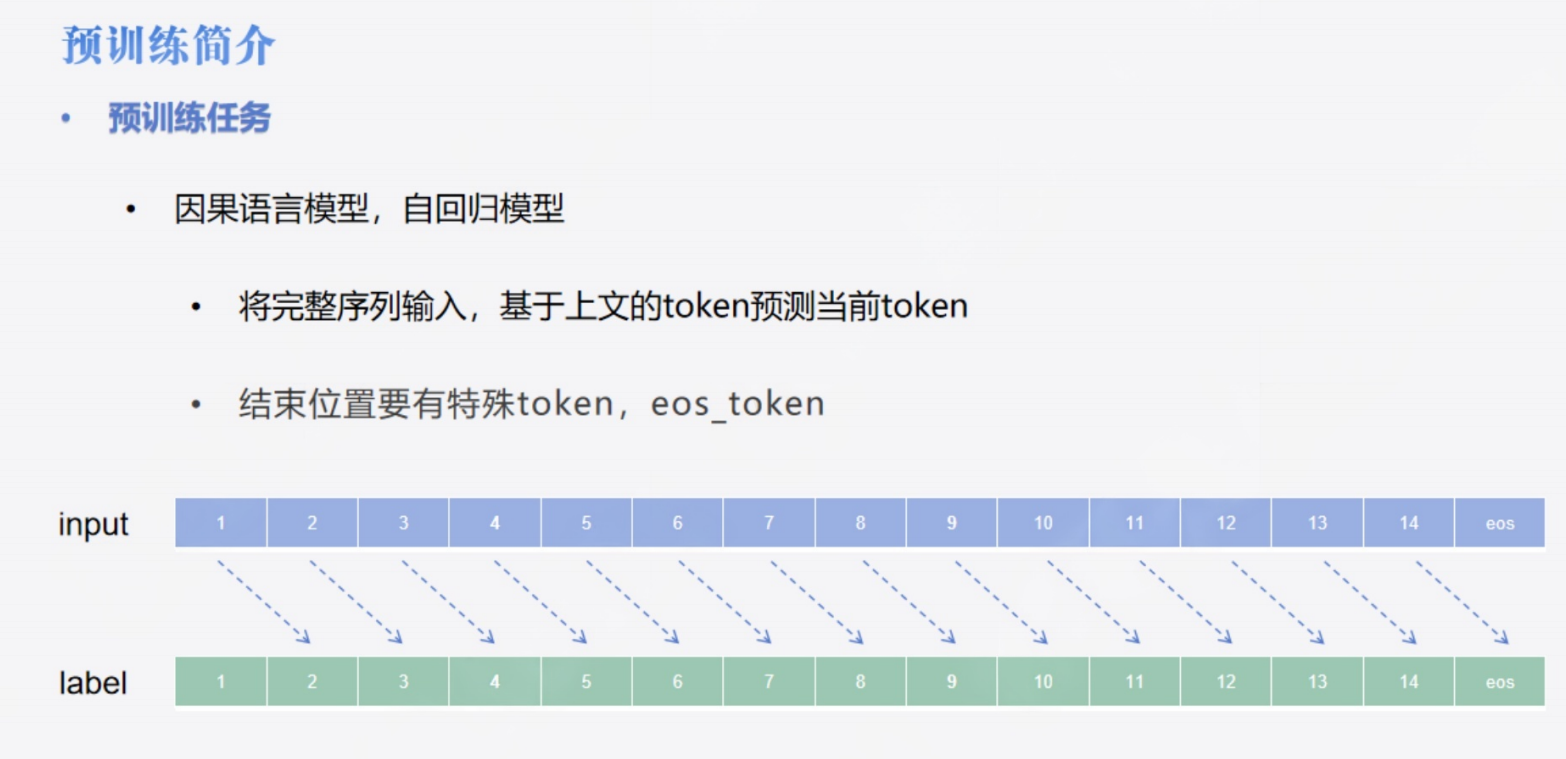


#### 3.2 数据加载与观察

我们使用 `alpaca_data_zh` 数据集，它包含三个字段：`instruction`（指令）、`input`（上下文输入，可能为空）、`output`（回答）。

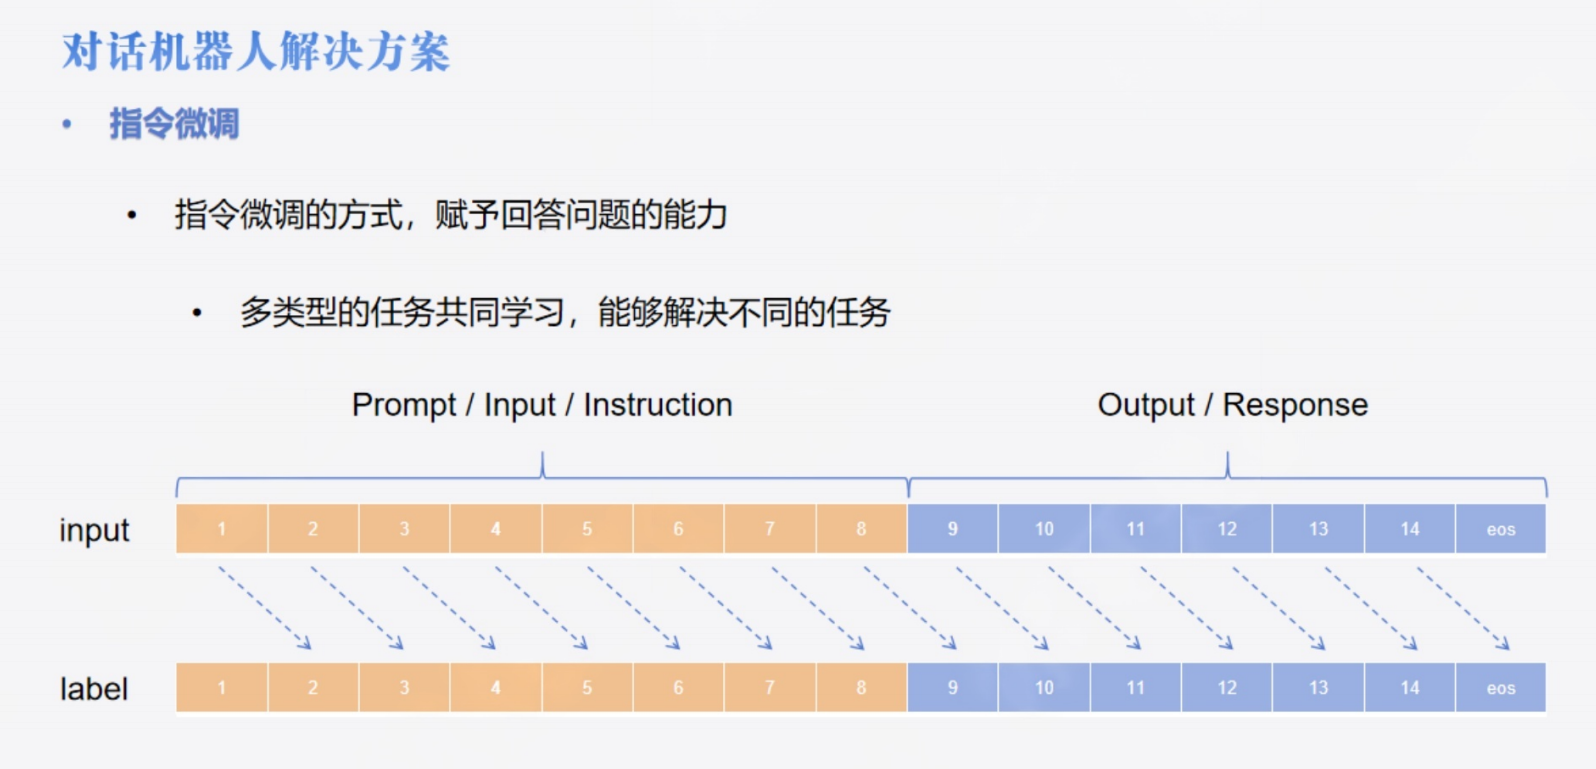


In [1]:
import os
# 必须在导入 torch 之前设置， 这样系统只会看到第一张 GPU，Trainer 就不会使用多 GPU。
os.environ['CUDA_VISIBLE_DEVICES'] = '0'

from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForCausalLM, DataCollatorForSeq2Seq, TrainingArguments, Trainer

# 加载本地数据集
ds = Dataset.load_from_disk("./alpaca_data_zh/")
# 查看数据示例
print(ds[:3])

{'output': ['以下是保持健康的三个提示：\n\n1. 保持身体活动。每天做适当的身体运动，如散步、跑步或游泳，能促进心血管健康，增强肌肉力量，并有助于减少体重。\n\n2. 均衡饮食。每天食用新鲜的蔬菜、水果、全谷物和脂肪含量低的蛋白质食物，避免高糖、高脂肪和加工食品，以保持健康的饮食习惯。\n\n3. 睡眠充足。睡眠对人体健康至关重要，成年人每天应保证 7-8 小时的睡眠。良好的睡眠有助于减轻压力，促进身体恢复，并提高注意力和记忆力。', '4/16等于1/4是因为我们可以约分分子分母都除以他们的最大公约数4，得到（4÷4）/ (16÷4）=1/4。分数的约分是用分子和分母除以相同的非零整数，来表示分数的一个相同的值，这因为分数实际上表示了分子除以分母，所以即使两个数同时除以同一个非零整数，分数的值也不会改变。所以4/16 和1/4是两种不同的书写形式，但它们的值相等。', '朱利叶斯·凯撒，又称尤利乌斯·恺撒（Julius Caesar）是古罗马的政治家、军事家和作家。他于公元前44年3月15日被刺杀。 \n\n根据历史记载，当时罗马元老院里一些参议员联合起来策划了对恺撒的刺杀行动，因为他们担心恺撒的统治将给罗马共和制带来威胁。在公元前44年3月15日（又称“3月的艾达之日”），恺撒去参加元老院会议时，被一群参议员包围并被攻击致死。据记载，他身中23刀，其中一刀最终致命。'], 'input': ['', '输入：4/16', ''], 'instruction': ['保持健康的三个提示。', '解释为什么以下分数等同于1/4', '朱利叶斯·凯撒是如何死亡的？']}


#### 3.3 核心难点：Prompt 构建与 Loss Masking

这是本任务最关键的数据预处理步骤。我们需要完成两件事：

1. **构建对话模版**：区分“人类”和“助手”的角色。格式通常为 `Human: {指令}\n\nAssistant: {回答}`。
    
2. **Loss Masking（标签掩码）**：为了让模型只学习如何“回答”，我们需要将 `Human` 部分的 Label 设置为 **\-100**。在 PyTorch 中，交叉熵损失函数会忽略值为 -100 的位置。
    

此外，必须在回答的末尾加上特殊的结束符（EOS Token），告知模型何时停止生成。

**代码实战：数据预处理函数**

In [2]:
model_tag = "Langboat/bloom-389m-zh"
model_path = "/3T/strange007/models/bloom-389m-zh/"

# 加载分词器 (Bloom-389m-zh)
tokenizer = AutoTokenizer.from_pretrained(model_path)

def process_func(example):
    MAX_LENGTH = 256
    input_ids, attention_mask, labels = [], [], []
    
    # 1. 构建 Instruction 部分 (Human)
    # 格式: Human: {instruction} {input} \n\nAssistant: 
    instruction = tokenizer("\n".join(["Human: " + example["instruction"], example["input"]]).strip() + "\n\nAssistant: ")
    
    # 2. 构建 Response 部分 (Assistant)
    # 格式: {output} + EOS_Token
    response = tokenizer(example["output"] + tokenizer.eos_token)
    
    # 3. 拼接 Input IDs 和 Attention Mask
    input_ids = instruction["input_ids"] + response["input_ids"]
    attention_mask = instruction["attention_mask"] + response["attention_mask"]
    
    # 4. 关键：构建 Labels
    # Instruction 部分设为 -100 (不计算 Loss)，Response 部分保留原 ID
    labels = [-100] * len(instruction["input_ids"]) + response["input_ids"]
    
    # 5. 长度截断
    if len(input_ids) > MAX_LENGTH:
        input_ids = input_ids[:MAX_LENGTH]
        attention_mask = attention_mask[:MAX_LENGTH]
        labels = labels[:MAX_LENGTH]
        
    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "labels": labels
    }

# 执行数据映射
tokenized_ds = ds.map(process_func, remove_columns=ds.column_names)

# 验证 Mask 逻辑：过滤掉 -100 后，解码出的应该是纯 Output 内容
print(tokenizer.decode(list(filter(lambda x: x != -100, tokenized_ds[1]["labels"]))))

4/16等于1/4是因为我们可以约分分子分母都除以他们的最大公约数4，得到（4÷4）/ (16÷4）=1/4。分数的约分是用分子和分母除以相同的非零整数，来表示分数的一个相同的值，这因为分数实际上表示了分子除以分母，所以即使两个数同时除以同一个非零整数，分数的值也不会改变。所以4/16 和1/4是两种不同的书写形式，但它们的值相等。</s>


## 以上代码——数据预处理流程

它的核心目的是：**构造符合“自回归（Causal Language Model）”训练格式的数据，并告诉模型“只学习如何回答，不要学习如何提问”。**

我们针对 Bloom（Decoder-only 架构模型）进行详细拆解：

* * *

### 1\. 核心逻辑总览

大模型（如 Bloom, Llama, GPT）的训练本质是\*\*“下一个词预测”\*\*（Next Token Prediction）。

训练时，我们输入一段完整的文本序列，模型需要预测每一个位置的下一个词是什么。

对于指令微调，我们希望模型学会的是：

看到 Human: ... (指令) 后，能够生成 Assistant: ... (回复)。

因此，数据处理的核心只有两件事：

1. **拼接**：把问题和答案拼成一长串。
    
2. **Masking（掩码）**：在计算 Loss（损失）时，**只计算“答案”部分的 Loss，忽略“问题”部分的 Loss**。
    
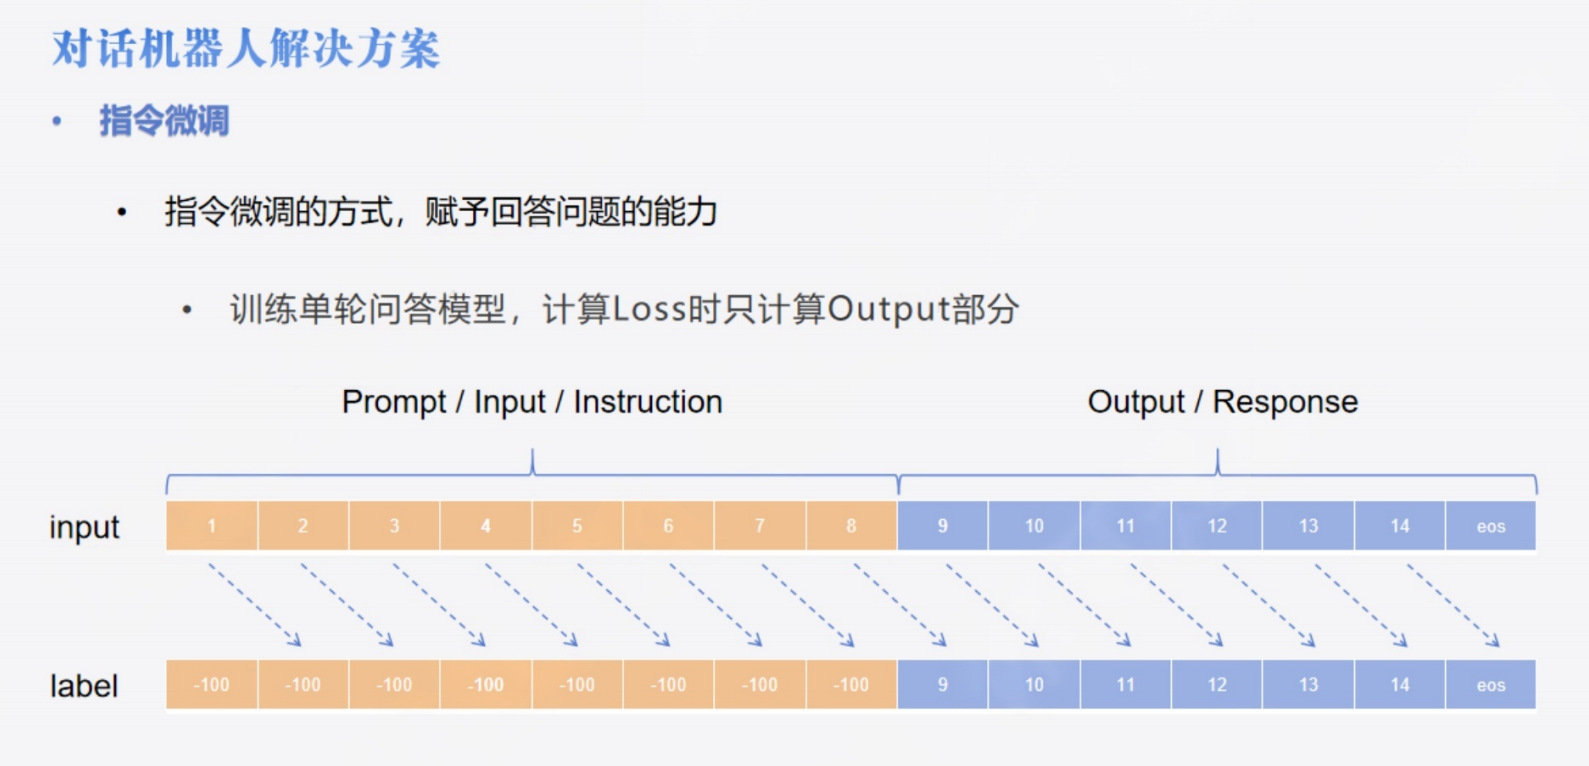

* * *

### 2\. 逐行深度解析

#### 第一步：构建指令（Prompt）

Python

```
# 格式: Human: {instruction} {input} \n\nAssistant: 
instruction = tokenizer("\n".join(["Human: " + example["instruction"], example["input"]]).strip() + "\n\nAssistant: ")
```

- **为什么要这样写？**
    
    - 这是为了构建**对话模板**。模型原本只会续写文本，通过固定的格式（Human/Assistant），我们让模型学会这种“一问一答”的模式。
        
    - `strip()` 是为了去除多余的空白符。
        
    - 这里的 `instruction` 变量包含了：`input_ids`（文字转成的数字列表）和 `attention_mask`。
        

#### 第二步：构建回复（Answer）

Python

```
# 格式: {output} + EOS_Token
response = tokenizer(example["output"] + tokenizer.eos_token)
```

- **为什么要加** `tokenizer.eos_token`？
    
    - **至关重要！** `eos_token` (End of Sentence) 是告诉模型“这就话说完了，请停止生成”。
        
    - 如果在训练数据中不加这个结束符，模型在推理时就会**停不下来**，说完答案后继续胡言乱语，直到达到最大长度限制。
        

#### 第三步：拼接（Concatenation）

Python

```
input_ids = instruction["input_ids"] + response["input_ids"]
attention_mask = instruction["attention_mask"] + response["attention_mask"]
```

- **原理**：
    
    - Bloom 是 **Decoder-only** 架构。它不像 BERT 分为输入和输出两段，也不像 T5 有 Encoder 和 Decoder。
        
    - 对 Bloom 来说，**输入就是一整条序列**。它并不区分哪部分是 Question，哪部分是 Answer，它只知道序列的前后关系。
        
    - 所以我们需要把 `[指令 ID]` 和 `[回复 ID]` 物理拼接在一起，形成一个完整的训练样本。
        

#### 第四步：构建 Labels（核心魔法：Loss Masking）

Python

```
labels = [-100] * len(instruction["input_ids"]) + response["input_ids"]
```

这是整段代码的**灵魂所在**。

- `labels` 是什么？
    
    - 在 PyTorch 训练中，`labels` 是用来和模型的输出计算 CrossEntropyLoss（交叉熵损失）的目标值。
        
- **为什么要填** `-100`？
    
    - 在 PyTorch 的 `CrossEntropyLoss` 函数中，有一个参数叫 `ignore_index`，默认值就是 **\-100**。
        
    - **凡是 Label 为 -100 的位置，梯度都不会回传，Loss 也就是 0。**
        
- **为什么要这样写？**
    
    - `[-100] * len(instruction["input_ids"])`：这一段对应的是“Human: ... Assistant:”的部分。我们**不希望**模型去学习如何预测这些已知的问题（Prompt）。这些是提示词，模型不需要对它们负责。
        
    - `+ response["input_ids"]`：这一段对应的是“实际回答 + EOS”。这才是我们希望模型学习生成的未知内容。
        
    - **结论**：这种技术叫 **Training on Completions Only**（仅在完成部分训练）。它可以显著提高微调的效率，让模型专注于学习“如何回答”，而不是浪费算力去“记忆问题”。
        

#### 第五步：截断（Truncation）

Python

```
if len(input_ids) > MAX_LENGTH:
    input_ids = input_ids[:MAX_LENGTH]
    attention_mask = attention_mask[:MAX_LENGTH]
    labels = labels[:MAX_LENGTH]
```

- **原理**：显存是有限的，模型的上下文窗口也是有限的。超过长度的数据必须切掉，否则会报错（OOM 或 Index Error）。
    
- *注意：这里使用的是简单的截断。更高级的做法可能会从左边截断 Instruction 保留 Output，或者丢弃过长样本，视具体策略而定。*
    

* * *

### 3\. 图解示例

假设：

- **Instruction**: "你好" (Token IDs: `[10, 20]`)
    
- **Prompt 模版**: "Human: 你好\n\nAssistant:" (Token IDs: `[1, 5, 10, 20, 6, 7]`) -> 长度 6
    
- **Output**: "我是AI" (Token IDs: `[30, 40]`) + EOS (`[2]`) -> `[30, 40, 2]` -> 长度 3
    

**最终送入模型的数据结构：**

<table><tbody><tr><td><p><strong>位置</strong></p></td><td><p><strong>0</strong></p></td><td><p><strong>1</strong></p></td><td><p><strong>2</strong></p></td><td><p><strong>3</strong></p></td><td><p><strong>4</strong></p></td><td><p><strong>5</strong></p></td><td><p><strong>6</strong></p></td><td><p><strong>7</strong></p></td><td><p><strong>8</strong></p></td></tr><tr><td><p><strong>文本含义</strong></p></td><td><p>Human</p></td><td><p>:</p></td><td><p>你</p></td><td><p>好</p></td><td><p>\n</p></td><td><p>Asst</p></td><td><p><strong>我</strong></p></td><td><p><strong>是AI</strong></p></td><td><p><strong>[EOS]</strong></p></td></tr><tr><td><p><strong>Input IDs</strong></p></td><td><p>1</p></td><td><p>5</p></td><td><p>10</p></td><td><p>20</p></td><td><p>6</p></td><td><p>7</p></td><td><p><strong>30</strong></p></td><td><p><strong>40</strong></p></td><td><p><strong>2</strong></p></td></tr><tr><td><p><strong>Labels</strong></p></td><td><p><strong>-100</strong></p></td><td><p><strong>-100</strong></p></td><td><p><strong>-100</strong></p></td><td><p><strong>-100</strong></p></td><td><p><strong>-100</strong></p></td><td><p><strong>-100</strong></p></td><td><p><strong>30</strong></p></td><td><p><strong>40</strong></p></td><td><p><strong>2</strong></p></td></tr><tr><td><p><strong>是否算Loss</strong></p></td><td><p>❌</p></td><td><p>❌</p></td><td><p>❌</p></td><td><p>❌</p></td><td><p>❌</p></td><td><p>❌</p></td><td><p>✅</p></td><td><p>✅</p></td><td><p>✅</p></td></tr></tbody></table>

模型在训练时，看到 Input 位置 5 的时候，会尝试预测位置 6。此时 Label 是 30，不是 -100，所以计算 Loss，模型学会了：*“在 Human:你好...Assistant: 后面，应该接 '我'”*。

### 4\. 验证代码解析

Python

```
# 过滤掉 -100 后，解码
print(tokenizer.decode(list(filter(lambda x: x != -100, tokenized_ds[1]["labels"]))))
```

- 这句话是在做 **Sanity Check（健全性检查）**。
    
- 如果我们前面的逻辑写对了，`labels` 里只有“回复部分”是正常的 Token ID，其他都是 -100。
    
- `filter` 函数把 -100 筛掉，只剩下回复的 ID。
    
- `tokenizer.decode` 把这些 ID 转回文本。
    
- **预期结果**：你应该只能看到 **Dataset 中 output 列的内容**（加上可能的结束符）。如果看到了 input 的内容，说明 Mask 逻辑写错了；如果乱码，说明截断或拼接错了。

## 随堂作业

### 5.2.3 在训练生成式对话机器人时，进行指令微调（Instruction Tuning）的核心逻辑是：在计算 Loss 时，我们应该对哪个部分进行 Loss Masking（即将 Label 设为 -100）？

#### 2.4 模型与训练器配置

- 加载 `AutoModelForCausalLM` 模型。 
- 在 `Trainer` 中，我们使用 `DataCollatorForSeq2Seq`。
    - 虽然这是 Decoder 模型，但该 Collator 能正确处理 Padding 逻辑
    - 而 `DataCollatorForLanguageModeling` 可能会强制把 Label 设为与 Input 一致，不符合我们要 Mask 掉 Instruction 的需求。

In [3]:
# 加载模型
model = AutoModelForCausalLM.from_pretrained(model_path)

# 配置训练参数
args = TrainingArguments(
    output_dir="./chatbot",
    per_device_train_batch_size=4,
    gradient_accumulation_steps=8, # 显存优化：梯度累加
    logging_steps=10,
    num_train_epochs=2
)

# 创建训练器
trainer = Trainer(
    model=model,
    args=args,
    tokenizer=tokenizer,
    train_dataset=tokenized_ds,
    # 使用 Seq2Seq Collator 处理 Padding
    data_collator=DataCollatorForSeq2Seq(tokenizer=tokenizer, padding=True)
)


In [4]:

# 开始训练
trainer.train()

Step,Training Loss
10,3.172300
20,3.219600
30,3.106400
40,3.142700
50,3.059700
60,2.948300
70,2.909300
80,2.875600
90,2.790400
100,2.845400


TrainOutput(global_step=1678, training_loss=2.111879908569663, metrics={'train_runtime': 1375.31, 'train_samples_per_second': 39.057, 'train_steps_per_second': 1.22, 'total_flos': 1.164486099812352e+16, 'train_loss': 2.111879908569663, 'epoch': 1.9991064780342516})

#### 2.5 模型推理

训练完成后，使用 `pipeline` 进行推理。
- 推理时，**必须**使用与训练时一致的 Prompt 格式（即 `Human: ... Assistant:`），否则模型无法正确识别生成的起点。

In [ ]:
from transformers import pipeline

# 创建生成 Pipeline
pipe = pipeline("text-generation", model=model, tokenizer=tokenizer, device=0)

# 构造推理输入：保持与训练数据一致的格式
ipt = "Human: {}\n{}".format("考试有哪些技巧？", "").strip() + "\n\nAssistant: "

# 执行生成
# do_sample=True 启用采样，增加回答的多样性
pipe(ipt, max_length=256, do_sample=True)

[{'generated_text': 'Human: 考试有哪些技巧？\n\nAssistant: 考试技巧包括许多不同的类型，以下是其中一些常见技巧的示例：\n\n1. 逻辑推理：考试一般要求学生对所指定的科目有详细的说明，并运用正确的推理方法来判断答案。\n\n2. 信息提取：学生可以将所指定内容复制粘贴到试题中，然后按照考试要求的步骤整理答案。\n\n3. 计算能力：考试通常要求学生计算和分析问题，计算能力是一项重要的能力。\n\n4. 时间管理：学生需要在规定的时间内进行考试，保持充足的睡眠和饮食，以便更好地完成考试。\n\n5. 阅读理解：学生需要仔细阅读题目，并对所指定的内容有充分的理解，理解能力的掌握对于考试的得分为非常有帮助。'}]

: 